# Assignment 1 — South German Credit
Data Science for Business · 2026–2027

Student 1: Flioris Vassily r1142362


Complete this notebook in Python. Keep your code and relevant outputs here; write the report in `A1_Template.docx`. The full instructions are in `A1_Assignment.pdf`.

In Colab: upload this `.ipynb` to Drive, open it with **Google Colaboratory**, then click **Connect**. Upload `South_German_Credit.csv` through **Files**. Locally, keep the CSV in the working folder or update `DATA_PATH`.


## Problem Overview


As consultants at Leuven Analytics Experts & Partners (LAE), help a regional bank explore credit risk, build a logistic regression model and explain it through a scorecard.

**Dataset.** `South_German_Credit.csv` — 1,000 credit records from 1973–1975.
- 21 columns: 20 predictors + 1 target.
- 700 good credits, 300 bad credits.
- No missing values.

**Predictors.**
- 3 quantitative: `duration` (months), `amount` (after an undocumented monotonic transformation,
  so not interpretable in DM), `age` (years).
- 17 categorical: stored as numeric category codes (status, credit_history, purpose, savings,
  employment_duration, installment_rate, personal_status_sex, other_debtors, present_residence,
  property, other_installment_plans, housing, number_credits, job, people_liable, telephone,
  foreign_worker).

**Target.** `credit_risk` — 0 = bad credit, 1 = good credit.

**Deliverables.**
1. Explore the data and split it 70/30 (stratified).
2. Build a logistic regression using WOE-encoded predictors, evaluate with IV, ROC and AUC.
3. Construct a scorecard (600 points at 50:1 good:bad odds, 20 points to double the odds) and
   verify it against the model probabilities.

## 0. Load the dataset
Run the two cells below, then start Question 1.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Add other imports as needed for your analysis.

In [2]:
DATA_PATH = Path("data/South_German_Credit.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Upload South_German_Credit.csv to the Colab Files panel, "
        "or set DATA_PATH to the CSV location on your computer."
    )

credit = pd.read_csv(DATA_PATH)
display(credit.head())

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


## 1. Explore the data

The bank wants to understand how applicant and loan characteristics relate to bad credit.

The goal here is to explore the data and explain one useful pattern before we touch any model.

#### 1. Load and check the data

Checks performd :
1. Load South_German_Credit.csv into your Python notebook. 
2. Check the dimensions, 
3. Check variable types, 
4. Check missing values, 
5. Check duplicate rows 
6. Check target counts. 
7. Create a modelling target with 1 = bad and 0 = good; keep the original credit_risk column. 
+ Record your checks and any action taken in the notebook.

In [3]:
# 1. loading (done in prev cell)

# 2. assert dim
print("Shape:", credit.shape)
assert credit.shape == (1000, 21), "Unexpected shape"

# 3. assert types
assert credit.dtypes.eq("int64").all(), f"Unexpected dtypes:\n{credit.dtypes}"

# 4. assery No missing values
assert credit.isna().sum().sum() == 0, "Missing values found"

# assert targ is strictly binary 0/1
assert set(credit["credit_risk"].unique()) == {0, 1}, "credit_risk not binary"

# 5. Duplicates — print the count once
dups = credit.duplicated().sum()  #returns bool if duplicates found
print("Duplicate rows:", dups)
assert dups == 0, f"Found {dups} duplicates — decide whether to drop or keep"

# 6. Target counts (700 good / 300 bad)
print("\ncredit_risk counts:\n", credit["credit_risk"].value_counts())
assert credit["credit_risk"].value_counts().to_dict() == {1: 700, 0: 300}, \
    "Target counts do not match the assignment (700 good / 300 bad)"

# 7. Modelling target: add a new column for bad credit, its the inverse of credit_risk
credit["bad"] = credit["credit_risk"].map({0: 1, 1: 0})     # map every value of initial credit_risk to its inverse within bad
assert credit["bad"].sum() == 300, "Expected 300 bad credits after flip"


Shape: (1000, 21)
Duplicate rows: 0

credit_risk counts:
 credit_risk
1    700
0    300
Name: count, dtype: int64


**Notes :**
- Shape is (1000,21) as expected.
- All columns are `int64`, even categorical variables.
- No duplicate rows. If yes the assert stops the codes and force us to deal with it.
- Target count : still 700 good and 300 bad credits.
- New column, "bad" with original `credit_risk` kept untouched.




#### 2. Keep a test sample separate

Before selecting predictors or exploring their relationship with the target, make a reproducible,
stratified 70% training / 30% test split. Record the random seed. Use this split throughout the
assignment: training data for exploration and model development, test data only for final
evaluation.

In [4]:
from sklearn.model_selection import train_test_split

SEED = 42

train, test = train_test_split(
    credit,
    test_size=0.30,
    stratify=credit["bad"],
    random_state=SEED,
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("\nTrain bad rate:", train["bad"].mean().round(4))
print("Test bad rate:", test["bad"].mean().round(4))

Train shape: (700, 22)
Test shape: (300, 22)

Train bad rate: 0.3
Test bad rate: 0.3


#### 3. Choose two variables and make one figure

Choose two variables and justify your choices. Define groups using the combination of both variables, grouping quantitative values or combining categories where appropriate. Make one clearly labelled figure showing each group's bad-credit rate and number of observations. Use descriptive category labels and explain your grouping choices.

#### 3.1 Variable typing

Before exploring relationships, I classify the predictors by their measurement type.
This classification is used later to decide how to group (Q1.3) and encode (Q2).

I define  4four groups:
- **Quantitative**: real measured values.
- **Binary categorical**: exactly two categories.
- **Ordinal categorical**: categories with a natural order.
- **Nominal categorical**: categories with no natural order.

In [5]:
quantitative_cols = [
    "duration",
    "amount",
    "age",
]

binary_categorical_cols = [
    "people_liable",
    "telephone",
    "foreign_worker",
]

ordinal_categorical_cols = [
    "status",                 # checking account balance, 1-none to 4-richest
    "credit_history",         # 0 past delays to 4 all repaid duly
    "savings",                # 1 none/unknown to 5 ≥ 1,000 DM
    "employment_duration",    # 1 unemployed to 5 ≥ 7 years
    "installment_rate",       # 1 ≥ 35% to 4 < 20% of income
    "present_residence",      # 1 < 1 year to 4 ≥ 7 years
    "property",               # 1 none to 4 real estate
    "number_credits",         # 1 = one credit to 4 = ≥ 6 credits
    "job",                    # 1 unskilled to 4 highly qualified
]

nominal_categorical_cols = [
    "purpose",
    "personal_status_sex",
    "other_debtors",
    "other_installment_plans",
    "housing",
]

categorical_cols = (
    binary_categorical_cols
    + ordinal_categorical_cols
    + nominal_categorical_cols
)

print("Quantitative:", len(quantitative_cols))
print("Binary:      ", len(binary_categorical_cols))
print("Ordinal:     ", len(ordinal_categorical_cols))
print("Nominal:     ", len(nominal_categorical_cols))
print("Total predictors:", len(quantitative_cols) + len(categorical_cols))

Quantitative: 3
Binary:       3
Ordinal:      9
Nominal:      5
Total predictors: 20


#### 3.2 EDA

1. Rank all variables using spread and monotonicity.
2. Re-group or re-combine variables if needed
3. Pick two from the top rankings and justify.
4. Make a graph 

**Spread :**
Spread is gonna help us see which variable explains the most the variance in the dataset (i.e. that separate "good creditor" form "bad" the best).

BUT :
- Low spread variables can be safely set aside, high-spread **ONLY** tells us we need to inspect it more.
- If a variable has the same bad rate as the original set (~30%), its spread is close to 0 and it doesn't carry any meaningful signal.
- spread a quick check but not enough alone (it only accounts the extreme values, not the middle ones, its also not comparable between variables with different level counts, and the extremes are often the smallest cells so a big spread can come from noise).
- we stay careful : spread is not "variance explained". It's just the range of the bad rate across levels. And a big spread doesn't mean the variable is good, it means it maybe it is.

**Monotonicity :**
Improves on the spread metric. Shows if the bad rate trends cleanly across ordered levels. A big spread with a broken middle (ex. like `duration` next cell) is less trustworthy than a big spread that goes cleanly up or down.
- It also shows 




In [6]:
def bad_rate_by_cat(df, col):
    """Bad rate and count per level. Rows ordered by level, NOT by bad rate."""
    tab = df.groupby(col)["bad"].agg(n="size", bad_rate="mean").reset_index()
    tab = tab.rename(columns={col: "level"})
    tab["level"] = tab["level"].astype(str)
    return tab.sort_values("level").reset_index(drop=True)

def bad_rate_by_quant(df, col, q=5):
    """Bad rate and count per quintile bin. Rows in bin order (which is natural)."""
    binned = pd.qcut(df[col], q=q, duplicates="drop")
    tab = df.groupby(binned)["bad"].agg(n="size", bad_rate="mean").reset_index()
    tab = tab.rename(columns={col: "level"})
    tab["level"] = tab["level"].astype(str)
    return tab

def spread_of(tab):
    return tab["bad_rate"].max() - tab["bad_rate"].min()


# -------------
rows = []
for col in categorical_cols:
    t = bad_rate_by_cat(train, col)
    if t["n"].min() >= 20:
        rows.append({"variable": col, "type": "categorical", "spread": spread_of(t)})

for col in quantitative_cols:
    t = bad_rate_by_quant(train, col)
    if t["n"].min() >= 20:
        rows.append({"variable": col, "type": "quantitative", "spread": spread_of(t)})

spreads = (
    pd.DataFrame(rows)
    .sort_values("spread", ascending=False)
    .reset_index(drop=True)
)
display(spreads)


# --------
top4 = spreads["variable"].head(4).tolist()

for col in top4:
    print(f"\n=== {col} ({'categorical' if col in categorical_cols else 'quantitative'}) ===")
    if col in categorical_cols:
        display(bad_rate_by_cat(train, col))
    else:
        display(bad_rate_by_quant(train, col))


# -----






,variable,type,spread
0,credit_history,categorical,0.507179
1,status,categorical,0.370364
2,other_debtors,categorical,0.292026
3,duration,quantitative,0.291545
4,savings,categorical,0.240234
5,property,categorical,0.235559
6,foreign_worker,categorical,0.200893
7,amount,quantitative,0.196584
8,employment_duration,categorical,0.180488
9,other_installment_plans,categorical,0.154999



=== credit_history (categorical) ===


,level,n,bad_rate
0,0,28,0.642857
1,1,38,0.552632
2,2,378,0.335979
3,3,57,0.298246
4,4,199,0.135678



=== status (categorical) ===


,level,n,bad_rate
0,1,193,0.492228
1,2,187,0.390374
2,3,41,0.195122
3,4,279,0.121864



=== other_debtors (categorical) ===


,level,n,bad_rate
0,1,639,0.300469
1,2,29,0.448276
2,3,32,0.156250



=== duration (quantitative) ===


,level,n,bad_rate
0,"(3.999, 12.0]",259,0.223938
1,"(12.0, 15.0]",50,0.180000
2,"(15.0, 24.0]",229,0.323144
3,"(24.0, 30.0]",39,0.282051
4,"(30.0, 72.0]",123,0.471545


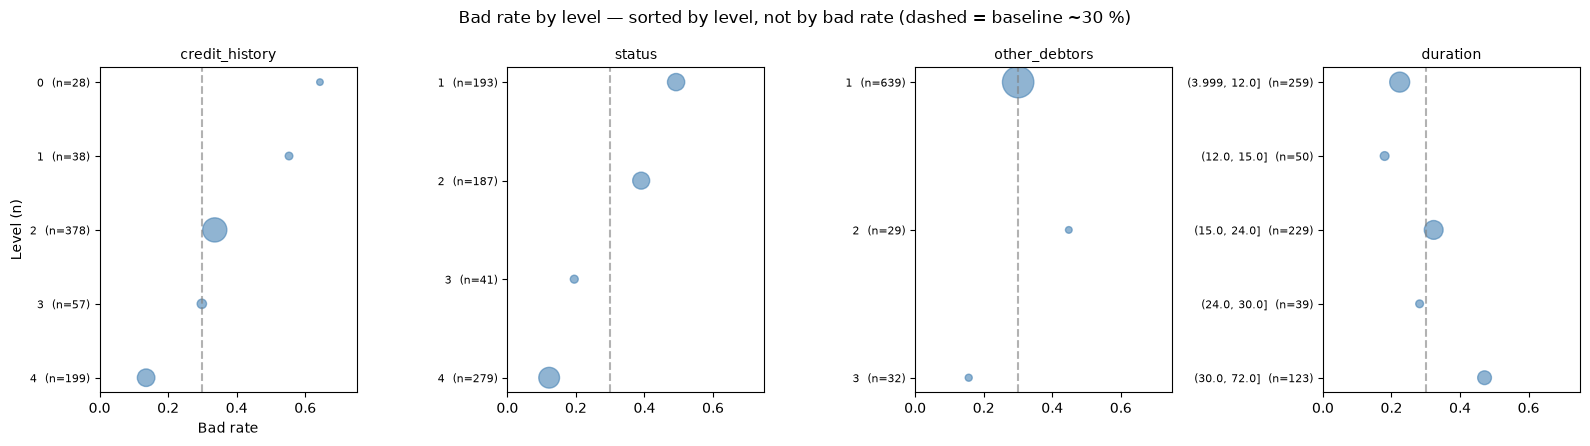

In [7]:
baseline = train["bad"].mean()
fig, axes = plt.subplots(1, len(top4), figsize=(4 * len(top4), 4.5), sharex=True)

for ax, col in zip(axes, top4):
    tab = bad_rate_by_cat(train, col) if col in categorical_cols else bad_rate_by_quant(train, col)

    y = list(range(len(tab)))
    ax.scatter(tab["bad_rate"], y, s=tab["n"] * 0.8, alpha=0.6, color="steelblue")
    ax.axvline(baseline, color="grey", linestyle="--", alpha=0.6, label="baseline")

    # y-axis: level name + n, so you can read every dot
    ax.set_yticks(y)
    ax.set_yticklabels([f"{lvl}  (n={n})" for lvl, n in zip(tab["level"], tab["n"])], fontsize=8)
    ax.set_title(col, fontsize=10)
    ax.set_xlim(0, 0.75)
    ax.invert_yaxis()   # first level at the top, like a table

axes[0].set_xlabel("Bad rate")
axes[0].set_ylabel("Level (n)")
fig.suptitle("Bad rate by level — sorted by level, not by bad rate (dashed = baseline ~30 %)")
plt.tight_layout()
plt.show()

Graph :
- the baseline at 30% represents the typical applicant. Below the baseline shows low-risk and above is high-risk.
- `credit_history`: is monotone, but assymetric, the high-risk side is small (~9%) compared to the low-risk.  

- `status` : monotone, no level sits on the baseline, symmetric and no tiny cell at the extremes.


- `other_debtors` : most population sits at baseline (~91%). Its spread comes form the 2 tiny cells at the extremes. 

- `duration` : also monotone, and symmetric. ts monotone slope is opposite to the ordinal categoricals, only because it has the opposite relation with risk (longer loan = higher risk).

#### 3.3 Variable choices


To illustrate, I choose the `credit_history` + `duration` variables :
- the bigger spread of `credit_history` and its assymetry makes it more interesting than `status`.
- `duration` is also a strong candidate, and this way we have One ordinal categorical + one quantitative to exercse both grouping techniques.


#### 3.4 Grouping choices

**Variable 1 - `credit_history`** :
- Categorical, ordinal — 5 codes (0–4) with a natural order.
- It has 4 categories (see `A1_Assignment.pdf`), we merge the ones with the same business meaning : 
- 0 (past delays) and 1 (critical account) --> both indicates previous problems.
- 2 (no credits / repaid duly) --> no credit history
- 3 and 4 --> both mean good history, reliable payer.


**Variable 2 - `duration`** :
- duration (quantitative) — bin into three business ranges, not five.
- Binned into 3 business ranges :
- Short ≤ 12 months
- Medium 13–24 months
- Long > 24 months

#### 3.5 Graph

In [8]:
# Grouping 
history_map = {0: "Previous problems", 1: "Previous problems",   # Group 0 and 1
                2: "No credit history",                         # No group
                3: "Reliable payer", 4: "Reliable payer"}      # group 3 and 4

def duration_bin(m):
    if m <= 12:   return "Short (≤12m)"
    elif m <= 24: return "Medium (13–24m)"
    else:         return "Long (>24m)"


In [9]:
# Graph
train["history_grp"]  = train["credit_history"].map(history_map)
train["duration_bin"] = train["duration"].apply(duration_bin)

group = (
    train
    .groupby(["history_grp", "duration_bin"])
    .agg(n=("bad", "size"), bad_rate=("bad", "mean"))
    .reset_index()
)
group["n_bad"] = (group["bad_rate"] * group["n"]).round().astype(int)

history_order  = ["Previous problems", "No credit history", "Reliable payer"]
duration_order = ["Short (≤12m)",     "Medium (13–24m)", "Long (>24m)"]
group["history_grp"]  = pd.Categorical(group["history_grp"],  categories=history_order,  ordered=True)
group["duration_bin"] = pd.Categorical(group["duration_bin"], categories=duration_order, ordered=True)
group = group.sort_values(["history_grp", "duration_bin"]).reset_index(drop=True)

group["label"] = group["history_grp"].astype(str) + "\n" + group["duration_bin"].astype(str)

#display(group)

clean = (
    group[["history_grp", "duration_bin", "n", "bad_rate", "n_bad"]]
    .copy()
)
clean["bad_rate"] = (clean["bad_rate"] * 100).round(1).astype(str) + " %"
clean = clean.rename(columns={
    "history_grp":  "History",
    "duration_bin": "Duration",
    "n":            "n",
    "bad_rate":     "Bad rate",
    "n_bad":        "Bad credits",
})
display(clean.reset_index(drop=True))



,History,Duration,n,Bad rate,Bad credits
0,Previous problems,Short (≤12m),19,57.9 %,11
1,Previous problems,Medium (13–24m),24,66.7 %,16
2,Previous problems,Long (>24m),23,52.2 %,12
3,No credit history,Short (≤12m),148,25.7 %,38
4,No credit history,Medium (13–24m),150,32.7 %,49
5,No credit history,Long (>24m),80,50.0 %,40
6,Reliable payer,Short (≤12m),92,9.8 %,9
7,Reliable payer,Medium (13–24m),105,17.1 %,18
8,Reliable payer,Long (>24m),59,28.8 %,17


Notes :
- This table combines the credit_history and the duration variables.
- ex. `Row 2` : creditors asking for a long-term loan and having bad payment history, 12/23 (~`52.2%`) failed on their payments
- ex. `Row 6` : creditors asking for a short-term loan and having good payment history, only 9/92 (~`9.8%`) failed on their payments

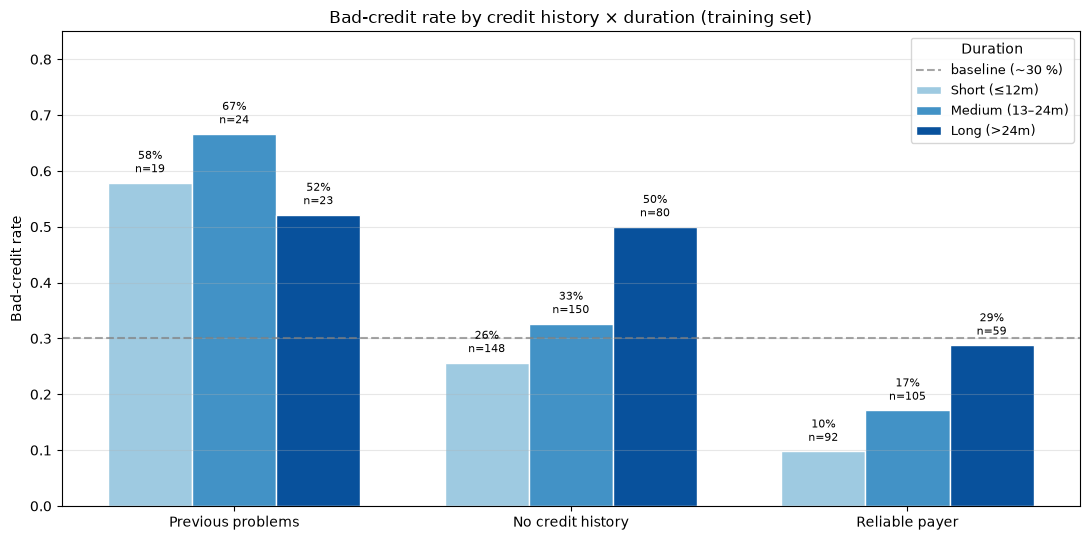

In [10]:
import matplotlib.pyplot as plt
import numpy as np

history_order  = ["Previous problems", "No credit history", "Reliable payer"]
duration_order = ["Short (≤12m)",     "Medium (13–24m)", "Long (>24m)"]

# consistent palette per duration bin (light → dark blue = short → long)
colors = {"Short (≤12m)": "#9ecae1", "Medium (13–24m)": "#4292c6", "Long (>24m)": "#08519c"}

fig, ax = plt.subplots(figsize=(11, 5.5))

n_hist   = len(history_order)
n_dur    = len(duration_order)
bar_w    = 0.25
x_center = np.arange(n_hist)

for j, dur in enumerate(duration_order):
    sub = group[group["duration_bin"].astype(str) == dur].set_index("history_grp")
    sub = sub.reindex(history_order)
    x   = x_center + (j - 1) * bar_w       # -1, 0, +1 offset
    bars = ax.bar(x, sub["bad_rate"], width=bar_w,
                  color=colors[dur], edgecolor="white", label=dur)

    for b, rate, n in zip(bars, sub["bad_rate"], sub["n"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
                f"{rate:.0%}\nn={int(n)}",
                ha="center", va="bottom", fontsize=8)

ax.axhline(train["bad"].mean(), color="grey", linestyle="--", alpha=0.7, label="baseline (~30 %)")
ax.set_xticks(x_center)
ax.set_xticklabels(history_order, fontsize=10)
ax.set_ylabel("Bad-credit rate")
ax.set_ylim(0, 0.85)
ax.set_title("Bad-credit rate by credit history × duration (training set)")
ax.legend(title="Duration", loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### 4. Interpret the evidence

Identify the group with the highest bad-credit rate and the group containing the most bad credits. Discuss the reliability of the pattern, considering group sizes and your grouping choices. Give one useful takeaway for the bank.

In [11]:
top_rate   = group.sort_values("bad_rate", ascending=False).iloc[0]
top_volume = group.sort_values("n_bad",     ascending=False).iloc[0]

def as_row(s, tag):
    return pd.DataFrame([{
        "Pick":           tag,
        "History":        s["history_grp"],
        "Duration":       s["duration_bin"],
        "n":              int(s["n"]),
        "Bad credits":    int(s["n_bad"]),
        "Bad rate":       f"{s['bad_rate']:.1%}",
    }])

comparison = pd.concat([as_row(top_rate,   "Highest bad-rate"), as_row(top_volume, "Largest bad-credit volume")], ignore_index=True,)

display(comparison)

,Pick,History,Duration,n,Bad credits,Bad rate
0,Highest bad-rate,Previous problems,Medium (13–24m),24,16,66.7%
1,Largest bad-credit volume,No credit history,Medium (13–24m),150,49,32.7%


Reliability : 
- The `highest bad rate` group (`row 0`) has a very small population (n=24), but has x2 higher rates (2/3).
- The `largest bad-credit volume` (`row 1`) has a bigger population (n=150), but has a lower bad rate (1/3).
- So the volume row is much more reliable, having a way bigger population count (`x6`). The highest rate row is noisier.

Takeaway for the bank : 
- The group for the bank to target depends on cost, how expensive is a bad loan to the bank versus reviewing appplicants.
- If reviews are cheap and bad loans expensive then it is better to target the big group, 49 bad loans avoided is better than 16, even if the rate is lower.
- The small group has a higher rate (2/3) but it's only 24 people, so the bank that only chases the highest rate is not looking for the most profitable answer.


Note :
- Why did both landed on the `medium` loan duration ? This is simply because more people choose for a medium-term loan (total n is 279).



---

## 2. Build and evaluate the model

Select predictors and use WOE to build and assess one logistic regression model for bad credit.




### 2.1 Select and transform your predictors

Binning strategy
- for our binning strategy, I follow Dimitri Bianco's method (https://www.youtube.com/watch?v=T__iiWXYam4).
- He showed a bottom-up binning strategy, where we start with fine bines and then iteratively merge adjacent bins until meeting a monotonic WoE, big enough cell sizes and maximizing IV.
- 




In [12]:
def woe_stats(df, col, target="bad", bins=None, bin_edges=None):
    """
    df        : training df
    col       : column to inspect
    bins      : optional Series of pre-assigned bins (for categorical — raw codes)
    bin_edges : optional list of numeric edges (for quantitative — custom cuts)
    If both bins and bin_edges are None, uses 10 quantile bins.
    """
    d = df.copy()
    if bins is not None:
        d["_bin"] = bins.values
    elif bin_edges is not None:
        d["_bin"] = pd.cut(d[col], bins=bin_edges, duplicates="drop")
    else:
        d["_bin"] = pd.qcut(d[col], q=10, duplicates="drop")

    tab = (d.groupby("_bin", observed=True)[target]
             .agg(n="size", bads="sum")
             .reset_index())
    tab["goods"]      = tab["n"] - tab["bads"]
    tab["bad_rate"]   = tab["bads"] / tab["n"]
    tab["goods_p"]    = tab["goods"] / tab["goods"].sum()
    tab["bads_p"]     = tab["bads"]  / tab["bads"].sum()
    tab["woe"]        = np.log((tab["goods_p"] + 1e-6) / (tab["bads_p"] + 1e-6))
    tab["iv_contrib"] = (tab["goods_p"] - tab["bads_p"]) * tab["woe"]

    # sort by the natural order of the bin (interval left / code value)
    if bins is not None:
        tab = tab.sort_values("_bin").reset_index(drop=True)
    else:
        tab = tab.sort_values("_bin").reset_index(drop=True)

    total_iv = tab["iv_contrib"].sum()
    return tab, total_iv

In [13]:
print("=" * 80)
print("QUANTITATIVE")
print("=" * 80)
for col in ["duration", "amount", "age"]:
    tab, iv = woe_stats(train, col)
    print(f"\n### {col}  —  IV (10 deciles) = {iv:.3f}")
    display(tab[["_bin", "n", "bads", "bad_rate", "goods_p", "bads_p", "woe", "iv_contrib"]]
              .round(4)
              .rename(columns={"_bin": "bin"}))

print("\n" + "=" * 80)
print("ORDINAL CATEGORICAL — raw codes, look for adjacent codes with close WOE")
print("=" * 80)
for col in ["status", "credit_history", "savings", "employment_duration",
            "installment_rate", "present_residence", "property",
            "number_credits", "job"]:
    tab, iv = woe_stats(train, col, bins=train[col])
    print(f"\n### {col}  —  IV (raw codes) = {iv:.3f}")
    display(tab[["_bin", "n", "bads", "bad_rate", "goods_p", "bads_p", "woe", "iv_contrib"]]
              .round(4)
              .rename(columns={"_bin": "code"}))

QUANTITATIVE

### duration  —  IV (10 deciles) = 0.288


,bin,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,"(3.999, 8.0]",72,8,0.1111,0.1306,0.0381,1.2321,0.1140
1,"(8.0, 12.0]",187,50,0.2674,0.2796,0.2381,0.1607,0.0067
2,"(12.0, 15.0]",50,9,0.1800,0.0837,0.0429,0.6690,0.0273
3,"(15.0, 18.0]",74,30,0.4054,0.0898,0.1429,-0.4643,0.0246
4,"(18.0, 24.0]",155,44,0.2839,0.2265,0.2095,0.0780,0.0013
5,"(24.0, 30.0]",39,11,0.2821,0.0571,0.0524,0.0870,0.0004
6,"(30.0, 36.0]",66,28,0.4242,0.0776,0.1333,-0.5419,0.0302
7,"(36.0, 72.0]",57,30,0.5263,0.0551,0.1429,-0.9526,0.0836



### amount  —  IV (10 deciles) = 0.123


,bin,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,"(249.999, 950.9]",70,24,0.3429,0.0939,0.1143,-0.1967,0.0040
1,"(950.9, 1275.0]",72,19,0.2639,0.1082,0.0905,0.1786,0.0032
2,"(1275.0, 1482.2]",68,16,0.2353,0.1061,0.0762,0.3314,0.0099
3,"(1482.2, 1870.0]",70,17,0.2429,0.1082,0.0810,0.2898,0.0079
4,"(1870.0, 2278.5]",70,18,0.2571,0.1061,0.0857,0.2136,0.0044
5,"(2278.5, 2780.2]",70,18,0.2571,0.1061,0.0857,0.2136,0.0044
6,"(2780.2, 3513.8]",70,17,0.2429,0.1082,0.0810,0.2898,0.0079
7,"(3513.8, 4587.4]",70,20,0.2857,0.1020,0.0952,0.0690,0.0005
8,"(4587.4, 7119.8]",70,28,0.4000,0.0857,0.1333,-0.4418,0.0210
9,"(7119.8, 18424.0]",70,33,0.4714,0.0755,0.1571,-0.7329,0.0598



### age  —  IV (10 deciles) = 0.138


,bin,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,"(18.999, 24.0]",98,37,0.3776,0.1245,0.1762,-0.3473,0.0180
1,"(24.0, 26.0]",59,22,0.3729,0.0755,0.1048,-0.3274,0.0096
2,"(26.0, 28.0]",62,19,0.3065,0.0878,0.0905,-0.0305,0.0001
3,"(28.0, 31.0]",80,29,0.3625,0.1041,0.1381,-0.2828,0.0096
4,"(31.0, 34.0]",74,24,0.3243,0.1020,0.1143,-0.1133,0.0014
5,"(34.0, 36.0]",59,9,0.1525,0.1020,0.0429,0.8675,0.0513
6,"(36.0, 40.0]",72,18,0.2500,0.1102,0.0857,0.2513,0.0062
7,"(40.0, 45.0]",64,17,0.2656,0.0959,0.0810,0.1696,0.0025
8,"(45.0, 52.0]",66,12,0.1818,0.1102,0.0571,0.6568,0.0348
9,"(52.0, 75.0]",66,23,0.3485,0.0878,0.1095,-0.2216,0.0048


... (14 outputs left out)


### number_credits  —  IV (raw codes) = 0.014


,code,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,1,445,140,0.3146,0.6224,0.6667,-0.0686,0.0030
1,2,235,66,0.2809,0.3449,0.3143,0.0929,0.0028
2,3,16,3,0.1875,0.0265,0.0143,0.6190,0.0076
3,4,4,1,0.2500,0.0061,0.0048,0.2513,0.0003



### job  —  IV (raw codes) = 0.016


,code,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,1,16,4,0.2500,0.0245,0.0190,0.2513,0.0014
1,2,137,37,0.2701,0.2041,0.1762,0.1470,0.0041
2,3,440,131,0.2977,0.6306,0.6238,0.0108,0.0001
3,4,107,38,0.3551,0.1408,0.1810,-0.2508,0.0101


Merging strategy :
1. merge bins with n<35 with the closest WoE-noeighbor.
2. merge zigzags, when WoE goes up and down by more than 0.15, the middle bin is noise and we merge with its closest WoE.
3. try to keep 2-4 bins minimum.
4. Increase for monotone WoE
5. drop variables with IV < 0.02

In [ ]:
def duration_bin4(m):
    if   m <= 8:  return "Very short (≤8m)"
    elif m <= 15: return "Short (9–15m)"
    elif m <= 30: return "Medium (16–30m)"
    else:         return "Long (>30m)"

def amount_bin2(x):
    return "Low–mid (≤4587)" if x <= 4587 else "High (>4587)"

def age_bin2(a):
    return "Young (≤34)" if a <= 34 else "Older (≥35)"

history_map_v2 = {
    0: "Previous problems", 1: "Previous problems",
    2: "Stable / no history", 3: "Stable / no history",
    4: "Reliable payer",
}
savings_map_v2 = {
    1: "No / small savings", 2: "No / small savings",
    3: "Real savings", 4: "Real savings", 5: "Real savings",
}
empdur_map_v2 = {
    1: "Unstable", 2: "Unstable",
    3: "Medium 1–4y",
    4: "Stable ≥4y", 5: "Stable ≥4y",
}
property_map_v2 = {
    1: "No property",
    2: "Car / insurance", 3: "Car / insurance",
    4: "Real estate",
}
status_map_v2 = {
    1: "No account", 2: "Overdrawn",
    3: "Low balance (0–200)", 4: "Healthy (≥200)",
}

leveling_all = {
    "status":              status_map_v2,
    "credit_history":      history_map_v2,
    "savings":             savings_map_v2,
    "property":            property_map_v2,
    "duration":            duration_bin4,
    "amount":              amount_bin2,
    "employment_duration": empdur_map_v2,
    "age":                 age_bin2,
}

---

In [15]:
def compute_woe_iv(df, col, new_col, mapping):
    """Group by the level, compute %good, %bad, WOE and IV on train."""
    d = df.copy()
    if isinstance(mapping, dict):
        d[new_col] = d[col].map(mapping)
    else:
        d[new_col] = d[col].apply(mapping)

    tab = (d.groupby(new_col)["bad"]
             .agg(n="size", n_bad="sum")
             .reset_index())
    tab["n_good"] = tab["n"] - tab["n_bad"]
    total_bad  = tab["n_bad"].sum()
    total_good = tab["n_good"].sum()
    tab["pct_good"] = tab["n_good"] / total_good
    tab["pct_bad"]  = tab["n_bad"]  / total_bad

    eps = 1e-6   # avoid log(0)
    tab["woe"] = np.log((tab["pct_good"] + eps) / (tab["pct_bad"] + eps))
    tab["iv_contrib"] = (tab["pct_good"] - tab["pct_bad"]) * tab["woe"]

    iv = tab["iv_contrib"].sum()
    tab = tab.sort_values("woe").reset_index(drop=True)  # riskiest first
    return tab, iv

In [16]:
woe_tables = {}
iv_rows = []
for var, mapping in leveling_all.items():
    tab, iv = compute_woe_iv(train, var, f"{var}_lvl", mapping)
    woe_tables[var] = tab
    iv_rows.append({"variable": var, "iv": iv})

iv_table = (pd.DataFrame(iv_rows)
              .sort_values("iv", ascending=False)
              .reset_index(drop=True))
iv_table["strength"] = pd.cut(
    iv_table["iv"],
    bins=[-1, 0.02, 0.10, 0.30, 0.50, 999],
    labels=["useless", "weak", "medium", "strong", "suspicious"],
)
display(iv_table)

NameError: name 'leveling_all' is not defined

Notes :
- in order to select the best predictors, we compute WoE and IV for all of them.
- ethically, its probably best to drop some predictors based on sex our nationality, we create a separate dataset to measure their impact.
- the `status` predictor has a very high IV, which can be a sign of leakage. So we test its per-level bad-rates and confirm a clean monotone behavior, this reflects a really strong signal and not leakage, so we keep it in the model.

Dataset 1 - agressive dropping :
- this is a stress test, to measure how much we can reduce ffeatures before performance collapses.
- IV > 0.10

Dataset 2 - Main :
- IV > 0.02


Dataset 3 - ethical :
- same as the main but we keep the unethical variables as well.
- those predictors are `foreign_worker` and `personal_status_sex`. Both have a weak IV signal, which is good ethically speaking. We don't expect this model to perform much differently from Dataset 2.


In [ ]:
# Check if strong IV signal of `status` is leakage.
display(woe_tables["status"][["status_lvl", "n", "n_bad", "woe"]])

,status_lvl,n,n_bad,woe
0,No account,193,95,-0.816204
1,Overdrawn (<0 DM),187,73,-0.401557
2,Low balance (0–200 DM),41,8,0.569757
3,Healthy (≥200 DM),279,34,1.127596


In [ ]:
# Build the datasets 
sensitive_vars = ["personal_status_sex", "foreign_worker"]

aggressive_vars = iv_table.query("iv >= 0.10")["variable"].tolist()
main_vars       = iv_table.query("iv >= 0.02")["variable"].tolist()
main_vars       = [v for v in main_vars if v not in sensitive_vars]
unethical_vars  = main_vars + sensitive_vars

dataset_vars = {
    "aggressive": aggressive_vars,
    "main":       main_vars,
    "unethical":  unethical_vars,
}

for name, vs in dataset_vars.items(): print(f"{name:12s} ({len(vs)}): {vs}")

def build_woe_frame(df, variables, leveling, woe_tables):
    out = pd.DataFrame(index=df.index)
    for var in variables:
        tab = woe_tables[var]
        lvl_col = "level" if "level" in tab.columns else f"{var}_lvl"
        woe_map = dict(zip(tab[lvl_col], tab["woe"]))
        if isinstance(leveling[var], dict):
            levels = df[var].map(leveling[var])
        else:
            levels = df[var].apply(leveling[var])
        out[var] = levels.map(woe_map)
    return out

datasets = {}
for name, vs in dataset_vars.items():
    datasets[name] = {
        "vars":  vs,
        "train": build_woe_frame(train, vs, leveling_all, woe_tables),
        "test":  build_woe_frame(test,  vs, leveling_all, woe_tables),
    }


summary = pd.DataFrame([
    {"dataset": name,
     "n":       len(spec["vars"]),
     "NaN_train": spec["train"].isna().sum().sum(),
     "NaN_test":  spec["test"].isna().sum().sum(),
     "predictors": ", ".join(spec["vars"])}
    for name, spec in datasets.items()
])
display(summary)






aggressive   (5): ['status', 'credit_history', 'savings', 'property', 'duration']
main         (11): ['status', 'credit_history', 'savings', 'property', 'duration', 'amount', 'employment_duration', 'other_installment_plans', 'housing', 'purpose', 'age']
unethical    (13): ['status', 'credit_history', 'savings', 'property', 'duration', 'amount', 'employment_duration', 'other_installment_plans', 'housing', 'purpose', 'age', 'personal_status_sex', 'foreign_worker']


,dataset,n,NaN_train,NaN_test,predictors
0,aggressive,5,0,0,"status, credit_history, savings, property, dur..."
1,main,11,0,0,"status, credit_history, savings, property, dur..."
2,unethical,13,0,0,"status, credit_history, savings, property, dur..."


### 2.2 Fit and interpet one model

Fit a logistic regression model using only your selected WOE-transformed predictors.
Among the selected predictors, which has the highest training information value (IV)? Explain
what its WOE values tell you about which levels are more or less risky.

In [ ]:
#


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

results = {}
for name, spec in datasets.items():
    model = LogisticRegression(C=1e10, max_iter=1000)
    model.fit(spec["train"], train["bad"])

    p_train = model.predict_proba(spec["train"])[:, 1]
    p_test  = model.predict_proba(spec["test"])[:, 1]

    results[name] = {
        "model":   model,
        "p_train": p_train,
        "p_test":  p_test,
        "auc_train": roc_auc_score(train["bad"], p_train),
        "auc_test":  roc_auc_score(test["bad"],  p_test),
    }

comparison = pd.DataFrame([
    {"dataset": name,
     "n": len(datasets[name]["vars"]),
     "AUC_train": round(r["auc_train"], 4),
     "AUC_test":  round(r["auc_test"], 4),
     "gap":       round(r["auc_train"] - r["auc_test"], 4)}
    for name, r in results.items()
])
display(comparison)

,dataset,n,AUC_train,AUC_test,gap
0,aggressive,5,0.7851,0.7529,0.0322
1,main,11,0.8030,0.7649,0.0380
2,unethical,13,0.8162,0.7507,0.0654


Notes :
- We fitted three models based on our three datasets. 
- `Main` (11 predictors) wins on test AUC (0.7649), this means it generalizes best to unseen data.
- `Aggressive` (5) is close but slightly worse, showing that the most part of the signal comes from our best predictors, but not all of it.
- `Unethical` (13) has the highest training AUC (0.816), but the lowest on the test AUC (0.75), maybe indicating overfitting.
- The ethical variables carry no real predictive value, including them even worsen performance, excluding them makes the most sense here. 

#### Highest IV predictor :

In [ ]:
display(woe_tables["status"][["status_lvl", "n", "n_bad", "woe"]])

,status_lvl,n,n_bad,woe
0,No account,193,95,-0.816204
1,Overdrawn (<0 DM),187,73,-0.401557
2,Low balance (0–200 DM),41,8,0.569757
3,Healthy (≥200 DM),279,34,1.127596


Notes :
- The riskiest is the `no account` one, Where there (exp(-0.82)=0.44 and 1/0.44=2.3) bads are x2.3 times more represented than good.
- The safest is the `healthy`, where (exp(1.128) = 3.09) goods are x3.1 times more represented than bads.
- The levels that are in between shows a more equal representation of good and bad creditors.
- The pattern is clearly monotone, and shows storng positive and negative predictions, this explains why its IV values ws so high.
- For the bank, customers having a checking account is a strong sign of being a good creditor: 
- Having no account = no bank relationship = highest risk.


In [ ]:
coefs = pd.DataFrame({
    "variable":    datasets["main"]["vars"],
    "coefficient": results["main"]["model"].coef_[0]
}).sort_values("coefficient")
display(coefs)
print("\nIntercept:", results["main"]["model"].intercept_[0])

,variable,coefficient
9,purpose,-1.272602
2,savings,-0.859947
4,duration,-0.852564
0,status,-0.785435
1,credit_history,-0.767558
3,property,-0.731301
10,age,-0.625235
6,employment_duration,-0.568178
7,other_installment_plans,-0.405308
8,housing,-0.302067



Intercept: -0.8451759761812772


### 2.3 Evaluate the model

Plot the training and test ROC curves together in one figure, with their AUC values in the
legend. Explain how well the model distinguishes good from bad observations and whether the
difference suggests overfitting. Give one conclusion for the bank and one limitation.

In [ ]:
#

In [ ]:
# Your predictor selection, level definitions, WOE and IV calculations.

In [ ]:
# Your fitted model, interpretation support and ROC evaluation.

## 3. Construct the scorecard
Follow Question 3 on page 5. Use 600 points at good:bad odds of 50:1 and 20 points to double those odds. Verify the scorecard against model probabilities on all test rows and check its scale.

Put the full scorecard and test-score boxplots in report Part 3, highlighting the two cases requested. Keep derivations and checks here.


In [ ]:
# Your complete scorecard and verification on the test sample.

In [ ]:
# Your test-score boxplots and the two highlighted cases.

**Submission:** run all cells in order, check results and save with outputs. Email the notebook and report PDF to **andreas.goethals@kuleuven.be** by **10 November 2026, 23:59 Belgian time**.

Subject: `DSFB_A1_r1_r2`. Files: `A1_r1_r2.pdf` and `A1_r1_r2.ipynb`. Use your actual r-numbers, smaller first. Follow all guidelines on page 1.
